# Objectif 

Test de l'hypothèse de variété sur les données de la portion 5. 

L'objectif est de tester les performances de la méthode de localisation après projection dans un espace de dimension réduite. 


Date de création : 30/10/2026

In [1]:
import os
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

In [2]:
if os.name == "nt":  # Windows
    ROOT_PROGRAM = r"C:\Users\baptiste.menetrier\Desktop\devPy\phd"
else:  # Linux
    ROOT_PROGRAM = "/home/program/ubf_tools"
sys.path.append(ROOT_PROGRAM)

from publication.publication_figure import set_subfigures_abc_labels, color
from real_data_analysis.acouplane.src.acouplane_cst import *
from real_data_analysis.acouplane.src.acouplane_utils import *

# from real_data_analysis.acouplane.src.acouplane_combination import (
#     combination_intersection_positions,
#     enumerate_rcv_combinations,
#     format_rcv_combination,
#     rcv_combination_records,
# )
# from real_data_analysis.acouplane.src.acouplane_conventions import library_event_error_mode
# from real_data_analysis.acouplane.src.acouplane_event import (
#     apply_mfp_strategy_to_portions,
#     build_portion_library,
#     derive_portion_cpsd_welch,
#     derive_portion_features,
#     get_crossing_distance_m,
# )
# from real_data_analysis.acouplane.src.acouplane_localization import (
#     add_validity_column,
#     select_and_order_distance_types,
#     summarize_localization_errors,
# )
# from real_data_analysis.acouplane.src.acouplane_plot_analysis import plot_metric_vs_n_rcv
# from real_data_analysis.acouplane.src.acouplane_plot_event import (
#     plot_event_features,
#     plot_library_and_event_map,
# )
# from real_data_analysis.acouplane.src.acouplane_plot_mfp import plot_combined_intersection_ambiguity
from real_data_analysis.acouplane.src.acouplane_portion_io import list_stored_intersections, open_portion
from real_data_analysis.acouplane.src.acouplane_features import (
    feature_distances_between_datasets,
)

# Chargement des données 

Les données sont stockées au format netcdf sous la forme d'un arbre (xarray DataTree) et regroupe l'ensemble des données associées à la portion d'intérêt. Les fichiers sont ouverts de façon paresseuse (rien n'est chargé en mémoire avant l'accès aux valeurs).

In [3]:
portion_id = 5
fpath = f"{ACOUPLANE_PORTION_NC_ROOT_FPATH}_{portion_id}.nc"
portion = open_portion(fpath)
portion

<xarray.DataTree>
Group: /
│   Attributes:
│       portion_filepath:  /home/program/ubf_tools/real_data_analysis/acouplane/d...
├── Group: /position
│   ├── Group: /position/sn0
│   │       Dimensions:                 (rcv_id: 7, atl_datetime: 2313, mmsi: 526,
│   │                                    ais_datetime: 241, src_datetime: 790)
│   │       Coordinates:
│   │         * rcv_id                  (rcv_id) <U4 112B 'obs1' 'obs2' ... 'obs7' 'tlq'
│   │         * atl_datetime            (atl_datetime) datetime64[ns] 19kB 2026-02-25T09:...
│   │         * ais_datetime            (ais_datetime) datetime64[ns] 2kB 2026-02-25T09:5...
│   │         * src_datetime            (src_datetime) datetime64[ns] 6kB 2026-02-25T09:5...
│   │       Dimensions without coordinates: mmsi
│   │       Data variables: (12/16)
│   │           rcv_lon                 (rcv_id) float64 56B ...
│   │           rcv_lat                 (rcv_id) float64 56B ...
│   │           rcv_immersion           (rcv_id) int16 14B ...
│   │           atl_lon                 (atl_datetime) float64 19kB ...
│   │           atl_lat                 (atl_datetime) float64 19kB ...
│   │           ais_lon                 (mmsi, ais_datetime) float64 1MB ...
│   │           ...                      ...
│   │           tir_src_lat             (src_datetime) float64 6kB ...
│   │           tir_vessel_lon          (src_datetime) float64 6kB ...
│   │           tir_vessel_lat          (src_datetime) float64 6kB ...
│   │           src_rcv_geodesic_dist   (rcv_id, src_datetime) float64 44kB ...
│   │           tps_propagation_s       (rcv_id, src_datetime) float64 44kB ...
│   │           tir_reception_datetime  (rcv_id, src_datetime) datetime64[ns] 44kB ...
│   │       Attributes:
│   │           description:              Positions AIS interpolées
│   │           interpolation_time_step:  10s
│   │           campagne:                 ACOUPLANE
│   │           geodesic_frame:           WGS84
│   │           portion_id:               5
│   │           section_orientation:      South/North
│   │           section_id:               0
│   │           section_label:            sn0
│   │           obs_position:             OBS position corrected using LMS inversion.
│   │           obs_position_filepath:    C:\Users\baptiste.menetrier\Desktop\devPy\phd\r...
│   ├── Group: /position/sn1
│   │       Dimensions:                 (rcv_id: 7, atl_datetime: 2120, mmsi: 526,
│   │                                    ais_datetime: 241, src_datetime: 800)
│   │       Coordinates:
│   │         * rcv_id                  (rcv_id) <U4 112B 'obs1' 'obs2' ... 'obs7' 'tlq'
│   │         * atl_datetime            (atl_datetime) datetime64[ns] 17kB 2026-02-25T11:...
│   │         * ais_datetime            (ais_datetime) datetime64[ns] 2kB 2026-02-25T11:1...
│   │         * src_datetime            (src_datetime) datetime64[ns] 6kB 2026-02-25T11:1...
│   │       Dimensions without coordinates: mmsi
│   │       Data variables: (12/16)
│   │           rcv_lon                 (rcv_id) float64 56B ...
│   │           rcv_lat                 (rcv_id) float64 56B ...
│   │           rcv_immersion           (rcv_id) int16 14B ...
│   │           atl_lon                 (atl_datetime) float64 17kB ...
│   │           atl_lat                 (atl_datetime) float64 17kB ...
│   │           ais_lon                 (mmsi, ais_datetime) float64 1MB ...
│   │           ...                      ...
│   │           tir_src_lat             (src_datetime) float64 6kB ...
│   │           tir_vessel_lon          (src_datetime) float64 6kB ...
│   │           tir_vessel_lat          (src_datetime) float64 6kB ...
│   │           src_rcv_geodesic_dist   (rcv_id, src_datetime) float64 45kB ...
│   │           tps_propagation_s       (rcv_id, src_datetime) float64 45kB ...
│   │           tir_reception_datetime  (rcv_id, src_datetime) datetime64[ns] 45kB ...
│   │       Attributes:
│   │           description:              Posi

# Rappel de la position de la portion 

(<Figure size 1600x800 with 1 Axes>,
 <Axes: title={'center': 'OBS positions'}, xlabel='Longitude [°]', ylabel='Latitude [°]'>)

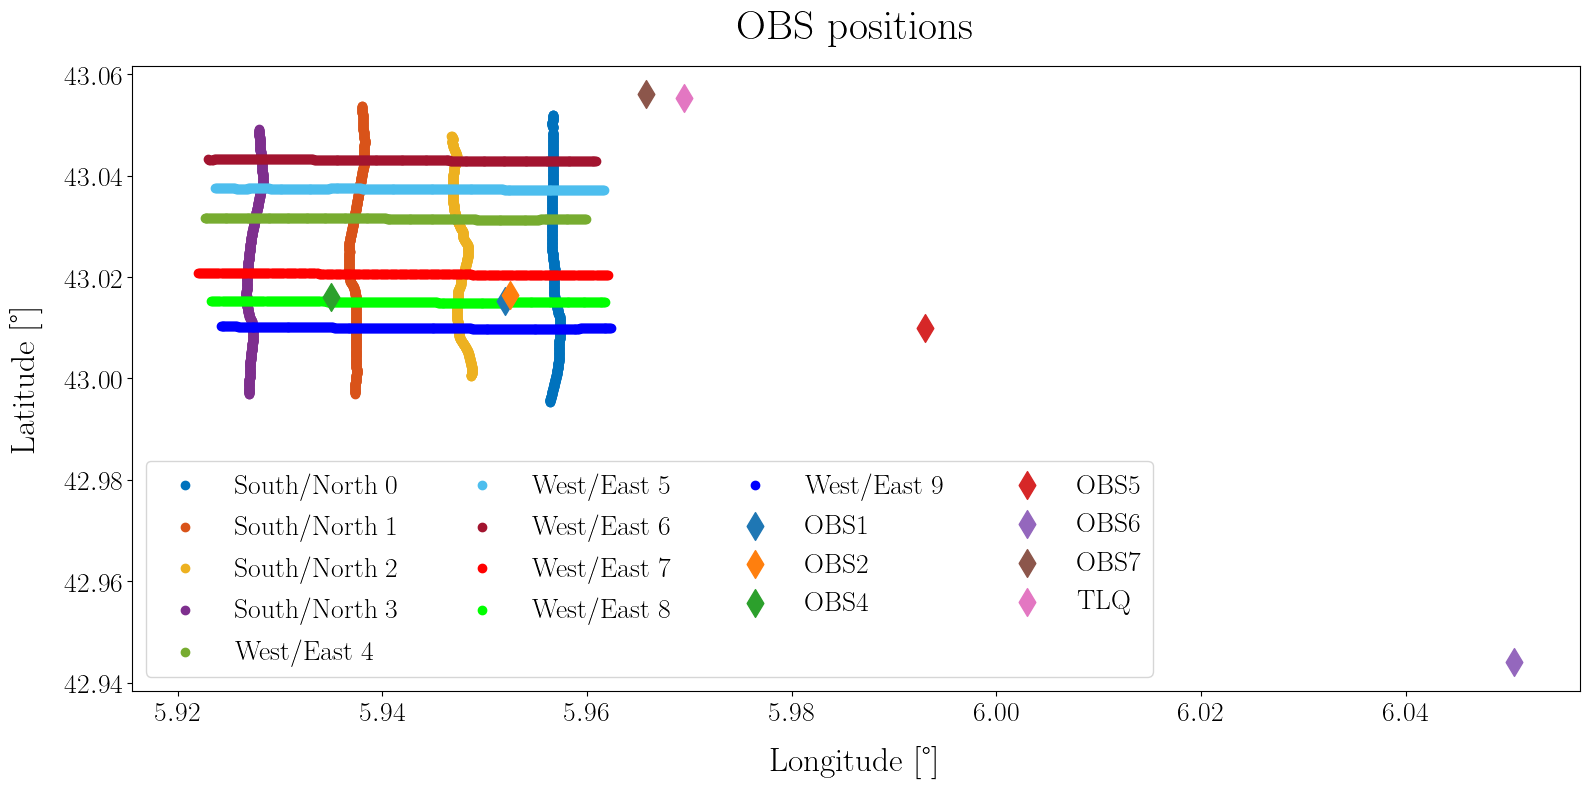

In [4]:
plot_portion_tir_pos(portion_tree=portion)

# Analyse de la structure de variété des données 

## Vérification de la dimension de la variété

Il s'agit dans un premier temps de vérifier si l'hypothèse de variété est respecté en considérant l'ensemble du jeu de donnée de la portion 5. 

### Définition de la méthode d'apprentissage de variété

On utilise ici la méthode ISOMAP qui à pour propriété (pour objectif) de préserver les distances géodésiques entre éléments du jeu de données. 

**Remarque** : on utilise ici le mode *metric = precomputed* qui permet de fournir directement une matrice de distance $M$ décrivant la distance entre chaque pair d'éléments du jeu de données.  

In [5]:
from sklearn import manifold
from sklearn.preprocessing import StandardScaler

# ISOMAP
n_components = 200
n_neighbors = 20

# Define isomap object
isomap_obj = manifold.Isomap(
    n_neighbors=n_neighbors,
    n_components=n_components,
    metric="precomputed",
)

### Calcul de la matrice des distances 

#### Paramètres 

In [6]:
receiver = "obs2"
fmin, fmax = 10, 200

#### Restriction de la portion aux paramètres d'étude 

In [7]:
portion_ = portion.sel(freq=slice(fmin, fmax))
portion_ = portion_.sel(rcv_id_feature=[receiver])
portion_.feature.sn0

<xarray.DataTree 'sn0'>
Group: /feature/sn0
    Dimensions:                 (rcv_id: 7, src_datetime: 787, rcv_i: 6, rcv_j: 6,
                                 freq: 779, rcv_id_feature: 1)
    Coordinates:
      * rcv_id                  (rcv_id) <U4 112B 'obs1' 'obs2' ... 'obs7' 'tlq'
      * src_datetime            (src_datetime) datetime64[ns] 6kB 2026-02-25T09:5...
      * rcv_i                   (rcv_i) <U4 96B 'obs1' 'obs2' ... 'obs6' 'obs7'
      * rcv_j                   (rcv_j) <U4 96B 'obs1' 'obs2' ... 'obs6' 'obs7'
      * freq                    (freq) float64 6kB 10.01 10.25 10.5 ... 199.7 200.0
      * rcv_id_feature          (rcv_id_feature) <U4 16B 'obs2'
    Data variables:
        rcv_lon                 (rcv_id) float64 56B ...
        rcv_lat                 (rcv_id) float64 56B ...
        rcv_immersion           (rcv_id) int16 14B ...
        tir_src_lon             (src_datetime) float64 6kB ...
        tir_src_lat             (src_datetime) float64 6kB ...
        src_rcv_geodesic_dist   (rcv_id, src_datetime) float64 44kB ...
        tps_propagation_s       (rcv_id, src_datetime) float64 44kB ...
        tir_reception_datetime  (rcv_id, src_datetime) datetime64[ns] 44kB ...
        Sxy                     (src_datetime, rcv_i, rcv_j, freq) complex64 177MB ...
        pi_ij                   (rcv_id_feature, src_datetime, freq) complex64 5MB ...
        gamma_ij                (rcv_id_feature, src_datetime, freq) float32 2MB ...
        sij_scot                (rcv_id_feature, src_datetime, freq) complex64 5MB ...
    Attributes:
        description:            Localisation features
        campagne:               ACOUPLANE
        geodesic_frame:         WGS84
        portion_id:             5
        section_orientation:    South/North
        section_id:             0
        section_label:          sn0
        obs_position:           OBS position corrected using LMS inversion.
        obs_position_filepath:  C:\Users\baptiste.menetrier\Desktop\devPy\phd\rea...
        reference_receiver:     obs1

#### Combinaison de toutes les sections 

On combine l'ensemble des sections d'intérêt afin de constituer le jeu de données étudié. 

In [22]:
selected_sections = ["sn0", "sn1", "sn2", "oe7", "oe8", "oe9"]
# Use all if none
if selected_sections is None:
    selected_sections = list(portion_.position.children)

var_to_keep = [
    "pi_ij",
    "gamma_ij",
    "sij_scot",
    "freq",
    "rcv_id_feature",
    "tir_src_lon",
    "tir_src_lat",
    "src_datetime",
]
var_to_drop = [
    var for var in list(portion_.feature[selected_sections[0]].to_dataset().variables) if var not in var_to_keep
]
sections_to_combined = []
for section in selected_sections:
    ds_section = portion_.feature[section].to_dataset()
    ds_section = ds_section.drop_vars(var_to_drop)
    sections_to_combined.append(ds_section)

ds_feature_combined = xr.concat(sections_to_combined, dim="src_datetime")
ds_feature_combined

<xarray.Dataset> Size: 54MB
Dimensions:         (src_datetime: 3437, rcv_id_feature: 1, freq: 779)
Coordinates:
  * src_datetime    (src_datetime) datetime64[ns] 27kB 2026-02-25T09:50:00.60...
  * rcv_id_feature  (rcv_id_feature) <U4 16B 'obs2'
  * freq            (freq) float64 6kB 10.01 10.25 10.5 ... 199.5 199.7 200.0
Data variables:
    tir_src_lon     (src_datetime) float64 27kB 5.957 5.957 ... 5.925 5.924
    tir_src_lat     (src_datetime) float64 27kB 43.05 43.05 ... 43.01 43.01
    pi_ij           (rcv_id_feature, src_datetime, freq) complex64 21MB (-0.5...
    gamma_ij        (rcv_id_feature, src_datetime, freq) float32 11MB -3.258 ...
    sij_scot        (rcv_id_feature, src_datetime, freq) complex64 21MB (-0.7...
Attributes:
    description:            Localisation features
    campagne:               ACOUPLANE
    geodesic_frame:         WGS84
    portion_id:             5
    section_orientation:    South/North
    section_id:             0
    section_label:          sn0
    obs_position:           OBS position corrected using LMS inversion.
    obs_position_filepath:  C:\Users\baptiste.menetrier\Desktop\devPy\phd\rea...
    reference_receiver:     obs1

In [9]:
feature_distances = feature_distances_between_datasets(
    ds_feature_a=ds_feature_combined,
    ds_feature_b=ds_feature_combined,
    compare_centered_gamma=True,
)

In [89]:
# Pick among available :['dist_theta',
#  'dist_theta_gamma',
#  'dist_L2_gamma',
#  'dist_dcf',
#  'dist_theta_gamma_centered',
#  'dist_L2_gamma_centered']
dist_metric = "dist_theta_gamma_centered"

dist_matrix = feature_distances[dist_metric]
# Remove rcv dimension = 1
dist_matrix = np.squeeze(dist_matrix)   
dist_matrix.shape

(3437, 3437)

### Importance relative des coordonnées en projection 

Pour ce faire, on peut commencer par projeter dans un espace de dimension importante (ici D = 200) et étudier l'importance relative de chacune des coordonnées. Pour ce faire, on utilise une approche similaire à l'approche de l'ACP et on représente la variance (ou bien de manière équivalente le pourcentage de variance cumulée) associé à chaque dimension. 

L'objectif est de vérifier que la variance décroit rapidement signifiant que les premières dimensions encode la majeure partie de l'information et que l'on peut donc réduire la dimension des données en préservant l'information importante à la localisation. 

In [90]:
# Learn manifold and project data in target dimension
coords = isomap_obj.fit_transform(dist_matrix)

# Normalize coords
norm_factor = np.max(coords)
coords /= norm_factor

C:\Users\baptiste.menetrier\AppData\Local\Temp\ipykernel_8100\606414193.py:7: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend()


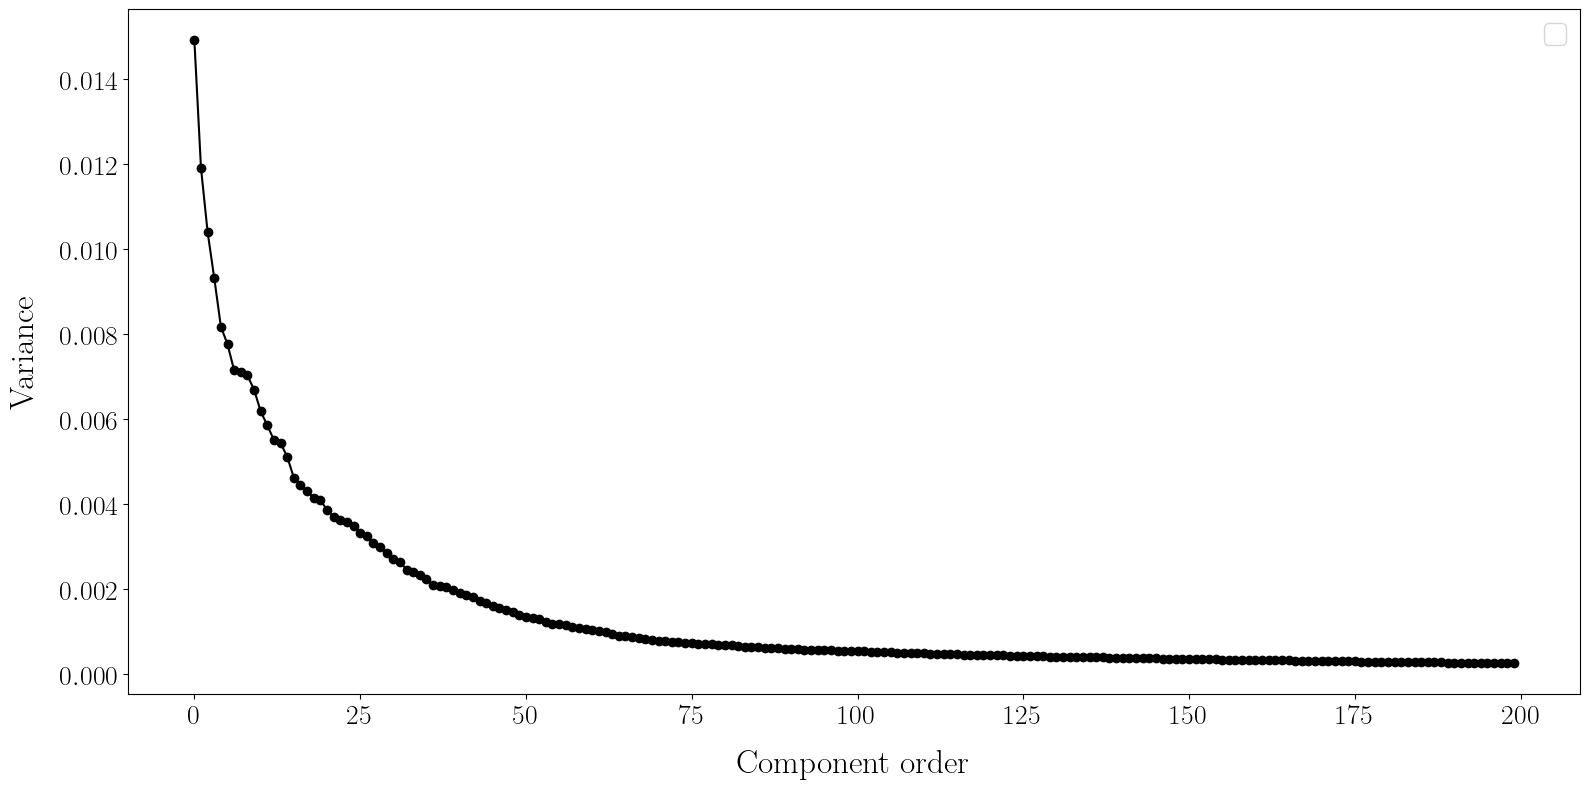

In [91]:
# Plot variance of each component
cvar = np.var(coords, axis=0)
plt.figure()
plt.plot(np.arange(cvar.size), cvar, marker="o", color="k")
plt.xlabel("Component order")
plt.ylabel("Variance")
plt.legend()
# plt.ylim(0, 0.05)

In [92]:
low_dim = 20
coords_low_dim = coords[:, :low_dim]
coords_low_dim.shape

dist_low_dim = np.sqrt(
    np.nansum(
        (coords_low_dim[:, np.newaxis, :] - coords_low_dim[np.newaxis, :, :]) ** 2,
        axis=-1,
    )
)

Text(0.02, 0.5, 'Replica index')

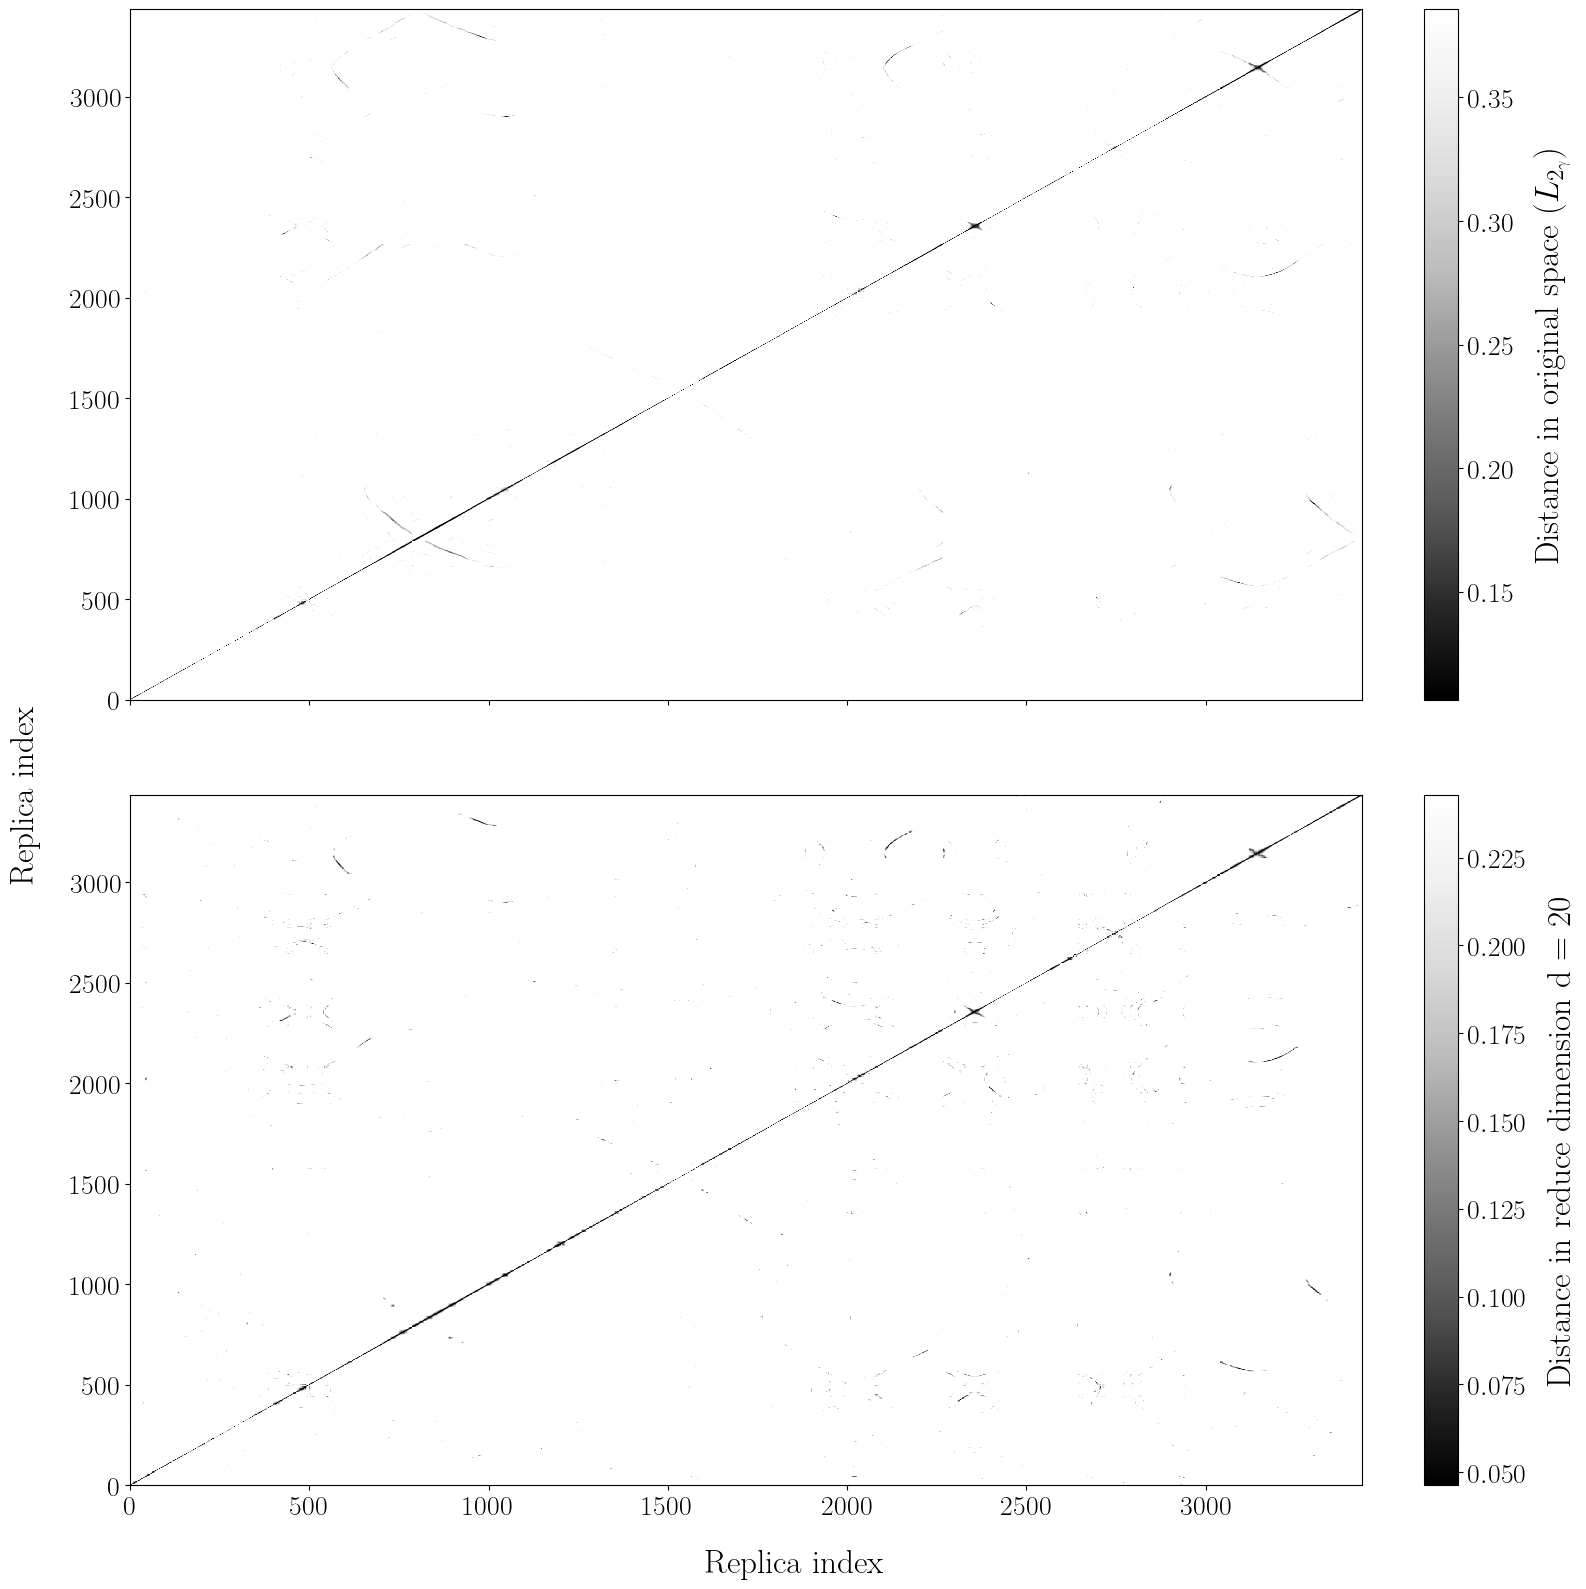

In [93]:
cmap = "Grays_r"
# cmap = "jet_r"
fig, axs = plt.subplots(2, 1, figsize=(16, 16), sharey=True, sharex=True)

# vmin = min(np.percentile(data, 0.05) for data in [dist_matrix, dist_low_dim])
# vmax = max(np.percentile(data, 0.95) for data in [dist_matrix, dist_low_dim])

# im = axs[0].pcolormesh(
#     dist_matrix, cmap="Grays_r", vmin=vmin, vmax=vmax
# )
# im = axs[1].pcolormesh(dist_low_dim, cmap="Grays_r", vmin=vmin, vmax=vmax)


# fig.colorbar(
#     im,
#     ax=axs[:].tolist(),
#     location="right",
#     label=r"$L_{2_\gamma}$",
#     pad=0.02,
#     fraction=0.04,
# )

# vmin = min(np.percentile(data, 0.05) for data in [dist_matrix, dist_low_dim])
# vmax = max(np.percentile(data, 0.95) for data in [dist_matrix, dist_low_dim])

im = axs[0].pcolormesh(
    dist_matrix,
    cmap=cmap,
    vmin=np.percentile(dist_matrix, 0.05),
    vmax=np.percentile(dist_matrix, 0.95),
)
plt.colorbar(im, label=r"Distance in original space ($L_{2_\gamma}$)", ax=axs[0])

im = axs[1].pcolormesh(
    dist_low_dim,
    cmap=cmap,
    vmin=np.percentile(dist_low_dim, 0.05),
    vmax=np.percentile(dist_low_dim, 0.95),
)
plt.colorbar(im, label=f"Distance in reduce dimension d = {low_dim}", ax=axs[1])

# fig.colorbar(
#     im,
#     ax=axs[:].tolist(),
#     location="right",
#     label=r"$L_{2_\gamma}$",
#     pad=0.02,
#     fraction=0.04,
# )

# plt.colorbar(im, label=f"Distance in reduce dimension d = {low_dim}")

fig.supxlabel("Replica index")
fig.supylabel("Replica index")

In [94]:
# Assign low_dim coordinates to corresponding section to analyse intersections
sections_to_combined = []
for section in selected_sections:
    ds_section = portion_.feature[section].to_dataset()
    ds_section = ds_section.drop_vars(var_to_drop)
    sections_to_combined.append(ds_section)

ds_feature_combined = xr.concat(sections_to_combined, dim="src_datetime")
ds_feature_combined

# coords_low_dim -> shape = (src_datetime_combined, low_dim)
idx_start_section = 0
idx_stop_section = 0
for ds_section in sections_to_combined:
    # Update stop
    idx_stop_section += ds_section.sizes["src_datetime"]
    # Extract section low dim coordinates
    coords_low_dim_section = coords_low_dim[idx_start_section:idx_stop_section, :]
    # Update start
    idx_start_section = idx_stop_section

    # Store
    ds_section.coords["isomap_dimension"] = np.arange(low_dim)
    ds_section["isomap_coords"] = (["src_datetime", "isomap_dimension"], coords_low_dim_section)

sn2 oe7


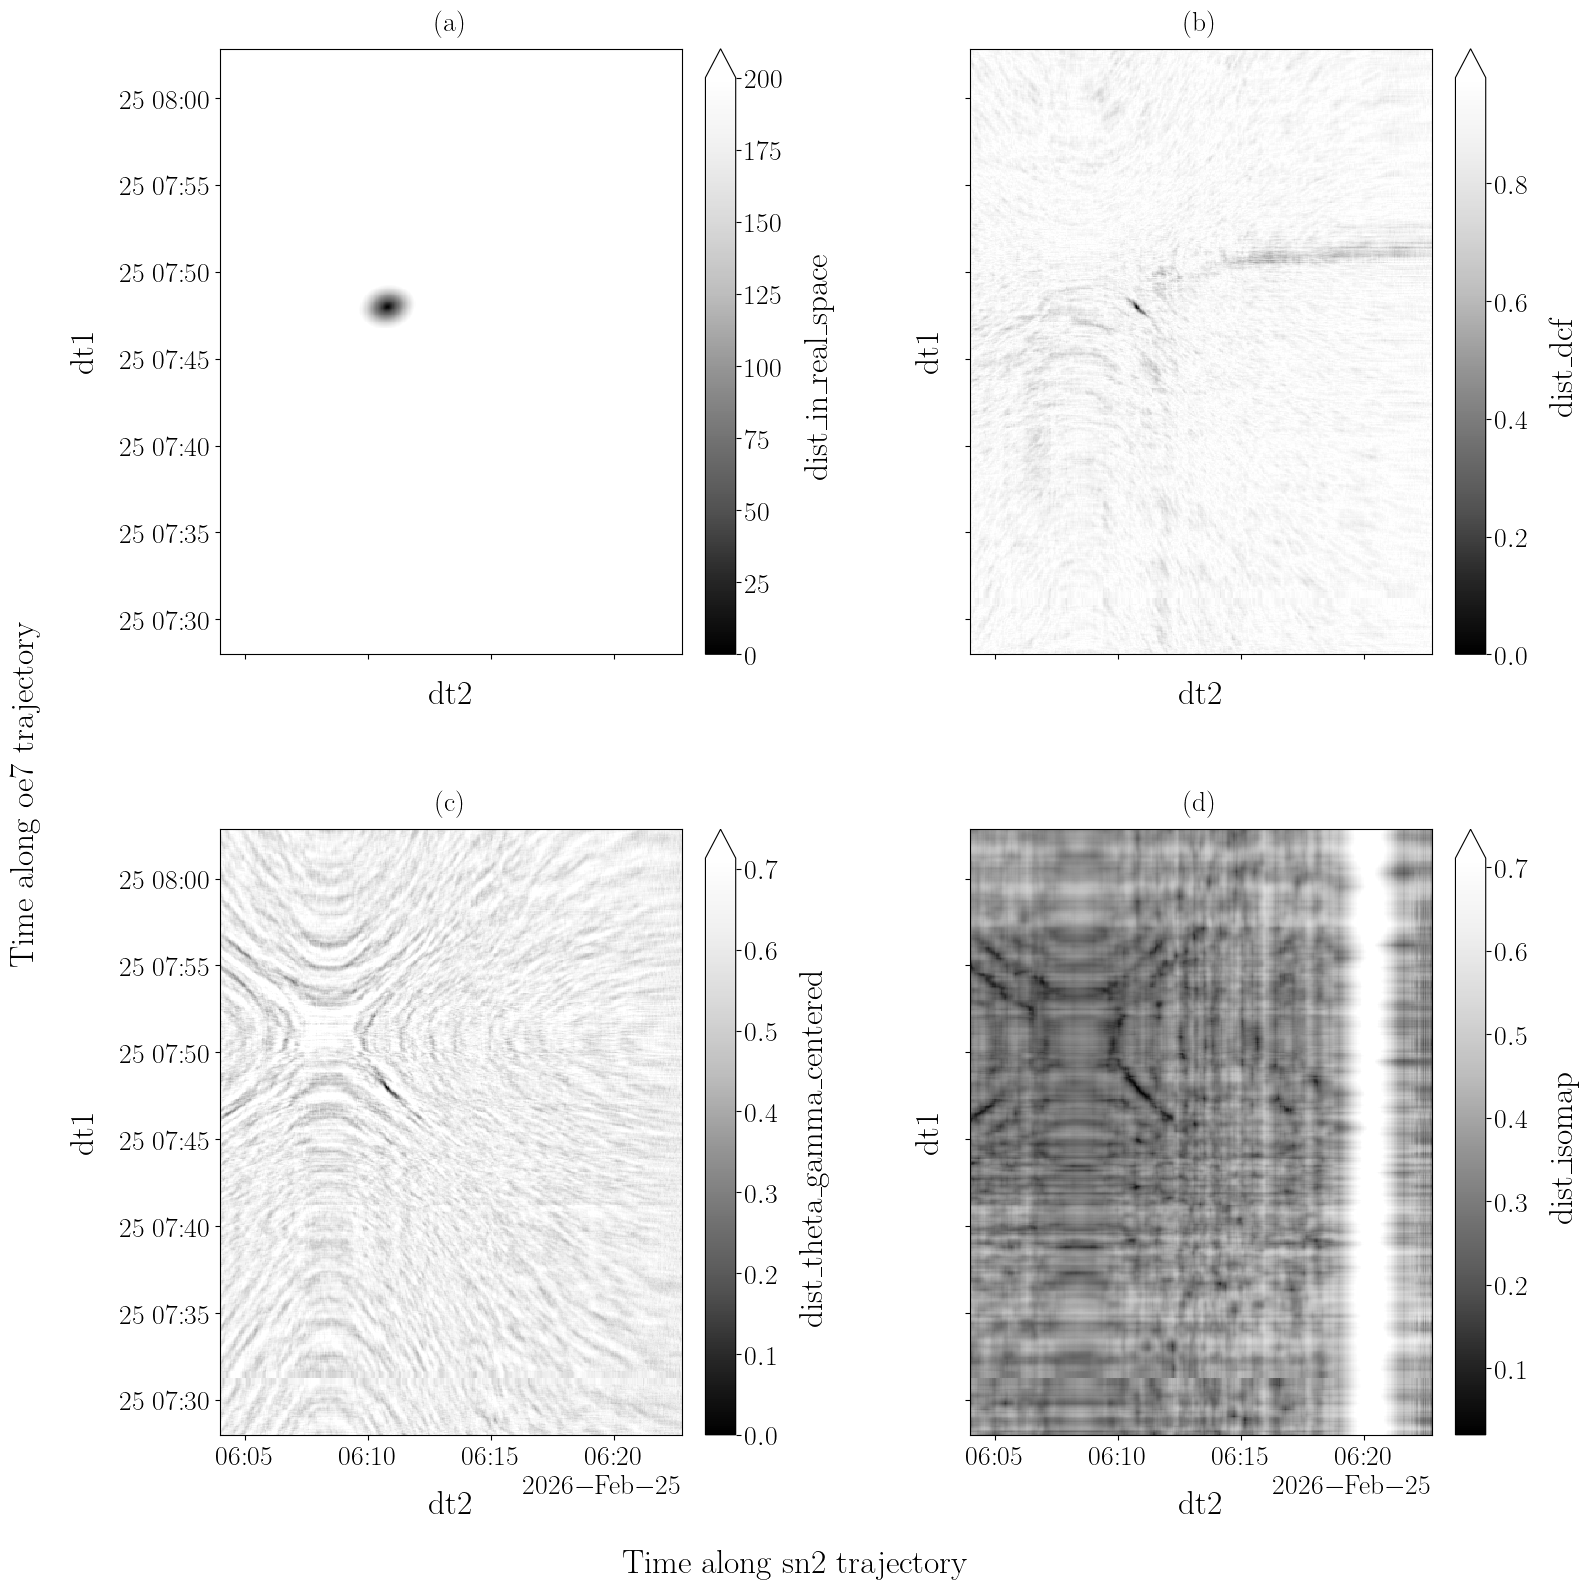

In [95]:
# for isec1, ds_section1 in enumerate(sections_to_combined):
# for isec1 in range(len(sections_to_combined)):

isec1 = 2
ds_section1 = sections_to_combined[isec1]
section1_name = selected_sections[isec1]

isec2 = 3
ds_section2 = sections_to_combined[isec2]
section2_name = selected_sections[isec2]

print(section1_name, section2_name)
# Original distance
distance_section12 = distances_single_intersection(
    ds_feature_section1=ds_section1,
    ds_feature_section2=ds_section2,
    compare_centered_gamma=True,
)

# Distance in low dimension using L2
d_L2_low_dim = np.sqrt(
    np.nansum(
        (
            ds_section1.isomap_coords.values[:, np.newaxis, :]
            - ds_section2.isomap_coords.values[np.newaxis, :, :]
        )
        ** 2,
        axis=-1,
    )
)
# Normalize
d_L2_low_dim /= np.nanmax(d_L2_low_dim)

data_vars = {
    d: (["dt1", "dt2"], np.squeeze(distance_section12[d]))
    for d in distance_section12.keys()
}
for k in data_vars.keys():
    if k != "dist_in_real_space":
        # data_vars[k] = (data_vars[k][0], data_vars[k][1]/ np.nanmax(data_vars[k][1]))
        data_vars[k] = (
            data_vars[k][0],
            (data_vars[k][1] - np.nanmin(data_vars[k][1]))
            / (np.nanmax(data_vars[k][1]) - np.nanmin(data_vars[k][1])),
        )

data_vars.update(dict(dist_isomap=(["dt1", "dt2"], d_L2_low_dim)))
ds_mfp = xr.Dataset(
    data_vars=data_vars,
    coords=dict(
        dt1=ds_section1.src_datetime.values, dt2=ds_section2.src_datetime.values
    ),
)

# Plot
cmap = "Grays_r"
max_quantile = 0.95
fig, axs = plt.subplots(
    nrows=2, ncols=2, figsize=(16, 16), sharex=True, sharey=True
)

ds_mfp.dist_in_real_space.plot(ax=axs[0, 0], cmap=cmap, vmin=0, vmax=200)
da = ds_mfp.dist_dcf
da.plot(
    ax=axs[0, 1],
    cmap=cmap,
    # vmin=0,
    # vmax=1,
    vmin=da.min(),
    vmax=da.quantile(q=max_quantile),
)
da = ds_mfp[dist_metric]
da.plot(
    ax=axs[1, 0],
    cmap=cmap,
    # vmin=0,
    # vmax=1,
    vmin=da.min(),
    vmax=da.quantile(q=max_quantile),
)
da = ds_mfp.dist_isomap
da.plot(
    ax=axs[1, 1],
    cmap=cmap,
    # vmin=0,
    # vmax=1,
    vmin=da.min(),
    vmax=da.quantile(q=max_quantile),
)

set_subfigures_abc_labels(
    axs, x_pos=0.5, y_pos=1.02, fontsize=20, ha="center", va="bottom"
)

fig.supxlabel(f"Time along {section1_name} trajectory")
fig.supylabel(f"Time along {section2_name} trajectory")

plt.show()

In [96]:
# # for isec1, ds_section1 in enumerate(sections_to_combined):
# for isec1 in range(len(sections_to_combined)):
#     ds_section1 = sections_to_combined[isec1]
#     section1_name = selected_sections[isec1]
#     # for isec2, ds_section2 in enumerate(sections_to_combined):
#     # # Avoid self comparison
#     # if isec1 == isec2:
#     #     continue
#     for isec2 in range(isec1 +1, len(sections_to_combined)):
#         ds_section2 = sections_to_combined[isec2]
#         section2_name = selected_sections[isec2]

#         # Original distance
#         distance_section12 = distances_single_intersection(
#             ds_feature_section1=ds_section1,
#             ds_feature_section2=ds_section2,
#             compare_centered_gamma=True,
#         )

#         # Distance in low dimension using L2
#         d_L2_low_dim = np.sqrt(
#             np.nansum(
#                 (
#                     ds_section1.isomap_coords.values[:, np.newaxis, :]
#                     - ds_section2.isomap_coords.values[np.newaxis, :, :]
#                 )
#                 ** 2,
#                 axis=-1,
#             )
#         )
#         # Normalize
#         d_L2_low_dim /= np.nanmax(d_L2_low_dim)

#         data_vars = {
#             d: (
#                 ["dt1", "dt2"],
#                 np.squeeze(distance_section12[d])
#             )
#             for d in distance_section12.keys()
#         }
#         for k in data_vars.keys():
#             if k != "dist_in_real_space":
#                 # data_vars[k] = (data_vars[k][0], data_vars[k][1]/ np.nanmax(data_vars[k][1]))
#                 data_vars[k] = (
#                     data_vars[k][0],
#                     (data_vars[k][1] - np.nanmin(data_vars[k][1]))
#                     / (np.nanmax(data_vars[k][1]) - np.nanmin(data_vars[k][1])),
#                 )

#         data_vars.update(dict(dist_isomap=(["dt1", "dt2"], d_L2_low_dim)))
#         ds_mfp = xr.Dataset(
#             data_vars=data_vars,
#             coords=dict(
#                 dt1=ds_section1.src_datetime.values, dt2=ds_section2.src_datetime.values
#             ),
#         )

#         # Plot
#         cmap = "Grays_r"
#         max_quantile = 0.95
#         fig, axs = plt.subplots(nrows=2, ncols=2, figsize=(16, 16), sharex=True, sharey=True)

#         ds_mfp.dist_in_real_space.plot(ax=axs[0, 0], cmap=cmap, vmin=0, vmax=200)
#         da = ds_mfp.dist_dcf
#         da.plot(
#             ax=axs[0, 1],
#             cmap=cmap,
#             vmin=0,
#             vmax=1,
#             # vmin=da.min(),
#             # vmax=da.quantile(q=max_quantile),
#         )
#         da = ds_mfp[dist_metric]
#         da.plot(
#             ax=axs[1, 0],
#             cmap=cmap,
#             vmin=0,
#             vmax=1,
#             # vmin=da.min(),
#             # vmax=da.quantile(q=max_quantile),
#         )
#         da = ds_mfp.dist_isomap
#         da.plot(
#             ax=axs[1, 1],
#             cmap=cmap,
#             vmin=0,
#             vmax=1,
#             # vmin=da.min(),
#             # vmax=da.quantile(q=max_quantile),
#         )

#         set_subfigures_abc_labels(
#             axs, x_pos=0.5, y_pos=1.02, fontsize=20, ha="center", va="bottom"
#         )

#         fig.supxlabel(f"Time along {section1_name} trajectory")
#         fig.supylabel(f"Time along {section2_name} trajectory")

#         plt.show()

In [97]:
# # dist_low_dim = np.sqrt(np.nansum((coords[:, np.newaxis, :] - coords[np.newaxis, :, :]) ** 2, axis=-1))

# low_dim = 5
# coords_low_dim = coords[:, :low_dim]
# coords_low_dim.shape

# # Split back into section 1 and section 2
# coords_low_dim_a = coords_low_dim[: gamma_a.shape[0], :]
# coords_low_dim_b = coords_low_dim[gamma_a.shape[0]:, :]

# # Compute L2 distance in low dimension
# dist_low_dim = np.sqrt(
#     np.nansum((coords_low_dim_a[:, np.newaxis, :] - coords_low_dim_b[np.newaxis, :, :]) ** 2, axis=-1)
# )

# xmin_low_dim, ymin_low_dim = find_min_distance_position(
#     dt1=ds_feature_section1.src_datetime,
#     dt2=ds_feature_section2.src_datetime,
#     dist=dist_low_dim.T,
# )

# # ind_min_low_dim = np.argmin(dist_low_dim.T)
# # xmin_low_dim, ymin_low_dim = xx.flatten()[ind_min_low_dim], yy.flatten()[ind_min_low_dim]

In [98]:
# # Plot to compare with dist_theta_gamma and dist_dcf

# # # vmin = max(np.nanmin(dist_theta_gamma), np.nanmin(dist_dcf))
# # # vmax = min(np.nanpercentile(dist_theta_gamma, 0.5), np.nanpercentile(dist_dcf, 0.5))

# # vmin = 0
# # vmax = 1

# fig, axs = plt.subplots(nrows=2, ncols=1, figsize=(16, 12), sharex=True, sharey=True)
# im = axs[0].pcolormesh(
#     ds_feature_section1.src_datetime,
#     ds_feature_section2.src_datetime,
#     dist_theta_gamma.T,
#     cmap="Grays_r",
#     # vmin=np.nanpercentile(dist_theta_gamma, 0.1),
#     vmin=np.nanmin(dist_theta_gamma),
#     vmax=np.nanpercentile(dist_theta_gamma, 0.9),
#     # vmin=vmin,
#     # vmax=vmax,
# )
# plt.colorbar(im, ax=axs[0], label=r"$\theta_{\gamma}$ in high dimension space")
# im = axs[1].pcolormesh(
#     ds_feature_section1.src_datetime,
#     ds_feature_section2.src_datetime,
#     dist_low_dim.T,
#     cmap="Grays_r",
#     vmin=np.nanmin(dist_low_dim),
#     vmax=np.nanpercentile(dist_low_dim, 0.9),
#     # vmin=vmin,
#     # vmax=vmax,
# )
# plt.colorbar(im, ax=axs[1], label=r"$L_2$ in reduced dimension space")

# # Common colorbar
# # plt.colorbar(im, ax=axs, label="Distance")

# axs[0].scatter(
#     xmin,
#     ymin,
#     marker="s",
#     s=400,
#     facecolors="none",
#     edgecolors="r",
#     label="Target",
#     linewidth=3,
# )
# axs[0].scatter(
#     xmin_theta_gamma,
#     ymin_theta_gamma,
#     marker="o",
#     s=200,
#     facecolors="none",
#     edgecolors="m",
#     label="Guess",
#     linewidth=3,
# )

# axs[1].scatter(
#     xmin_low_dim,
#     ymin_low_dim,
#     marker="o",
#     s=200,
#     facecolors="none",
#     edgecolors="m",
#     label="Guess",
#     linewidth=3,
# )
# axs[1].scatter(
#     xmin,
#     ymin,
#     marker="s",
#     s=400,
#     facecolors="none",
#     edgecolors="r",
#     label="Target",
#     linewidth=3,
# )

# for ax in axs.flatten():
#     ax.legend(loc="upper left", fontsize=14)

# fig.supxlabel(
#     f"Time along {ds_feature_section1.section_orientation} {ds_feature_section1.section_id} trajectory"
# )
# fig.supylabel(
#     f"Time along {ds_feature_section2.section_orientation} {ds_feature_section2.section_id} trajectory"
# )